In [5]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
activation_func = "decode_sigmoid"

batch_size = 256

trainset = datasets.MNIST("./dataset/", train = True, transform = transforms.ToTensor(), download = True)
#dataloader = torch.utils.data.DataLoader(trainset, batch_size = batch_size, shuffle = True, num_workers = 2)

testset = datasets.MNIST("./dataset/", train = False, transform = transforms.ToTensor(), download =   True)
#testloader = torch.utils.data.DataLoader(testset, batch_size = batch_size, shuffle = False, num_workers = 2)

dataset = torch.utils.data.ConcatDataset([trainset, testset])
dataloader = torch.utils.data.DataLoader(
    dataset,
    batch_size = 256,
    shuffle = True
)

tensor_to_img = transforms.ToPILImage()

In [7]:
class SAE(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder_layer_1 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(28 * 28, 500),
            nn.ReLU(),
        )

        self.decoder_layer_1 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(500, 28 * 28),
            nn.Sigmoid(),
        )

        self.encoder_layer_2 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(500, 500),
            nn.ReLU(),
        )

        self.decoder_layer_2 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(500, 500),
            nn.ReLU(),
        )

        self.encoder_layer_3 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(500, 2000),
            nn.ReLU(),
        )

        self.decoder_layer_3 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(2000, 500),
            nn.ReLU(),
        )

        self.encoder_layer_4 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(2000, 10),
        )

        self.decoder_layer_4 =  nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(10, 2000),
            nn.ReLU(),
        )

    def forward(self, x):
        encoded = self.encoder_layer_4(
                    self.encoder_layer_3(
                        self.encoder_layer_2(
                            self.encoder_layer_1(x)
                        )
                    )
                )

        decoded = self.decoder_layer_1(
                    self.decoder_layer_2(
                        self.decoder_layer_3(
                            self.decoder_layer_4(encoded)
                        )
                    )
                )
        return decoded
    
    def encode(self, x):
        e1 = self.encoder_layer_1(x)
        e2 = self.encoder_layer_2(e1)
        e3 = self.encoder_layer_3(e2)
        z = self.encoder_layer_4(e3)
        return z

# SAE Training

## Pretraining
Greedy layer-wise training

In [ ]:
model = SAE()
model.to(device)

# Pretraining
pretrain_epochs = 200

# Pretrain layer 1

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_1.parameters()) + 
    list(model.decoder_layer_1.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

model.train()
for epoch in range(pretrain_epochs):
    batch_losses = []
    
    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)
        e1 = model.encoder_layer_1(images)
        e1_reconstructed = model.decoder_layer_1(e1)
        loss = loss_function(e1_reconstructed, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 1: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre1")

        print(f"Best Pretrain 1 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")

# Pretrain layer 2

model.load_state_dict(torch.load("./models/" + activation_func + "/pre1", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_2.parameters()) + 
    list(model.decoder_layer_2.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()

for epoch in range(pretrain_epochs):
    batch_losses = []

    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)

        with torch.no_grad():
            e1 = model.encoder_layer_1(images)
        
        e2 = model.encoder_layer_2(e1)
        e1_reconstructed = model.decoder_layer_2(e2)

        loss = loss_function(e1_reconstructed, e1)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 2: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre2")

        print(f"Best Pretrain 2 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


# Pretrain layer 3

model.load_state_dict(torch.load("./models/" + activation_func + "/pre2", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_3.parameters()) + 
    list(model.decoder_layer_3.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()
model.encoder_layer_2.eval()

for epoch in range(pretrain_epochs):
    batch_losses = []

    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)

        with torch.no_grad():
            e1 = model.encoder_layer_1(images)
            e2 = model.encoder_layer_2(e1)
        
        e3 = model.encoder_layer_3(e2)
        e2_reconstructed = model.decoder_layer_3(e3)

        loss = loss_function(e2_reconstructed, e2)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 3: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre3")

        print(f"Best Pretrain 3 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


# Pretrain layer 4

model.load_state_dict(torch.load("./models/" + activation_func + "/pre3", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_4.parameters()) + 
    list(model.decoder_layer_4.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()
model.encoder_layer_2.eval()
model.encoder_layer_3.eval()

for epoch in range(pretrain_epochs):
    batch_losses = []

    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)

        with torch.no_grad():
            e1 = model.encoder_layer_1(images)
            e2 = model.encoder_layer_2(e1)
            e3 = model.encoder_layer_3(e2)
        
        e4 = model.encoder_layer_4(e3)
        e3_reconstructed = model.decoder_layer_4(e4)

        loss = loss_function(e3_reconstructed, e3)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Pretrain 4: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/pre4")

        print(f"Best Pretrain 4 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")

Pretrain 1: Epoch 1/200, Loss: 0.112115
Best Pretrain 1 Epoch: 1/200, Loss: 0.112115
Pretrain 1: Epoch 2/200, Loss: 0.068646
Best Pretrain 1 Epoch: 2/200, Loss: 0.068646
Pretrain 1: Epoch 3/200, Loss: 0.063586
Best Pretrain 1 Epoch: 3/200, Loss: 0.063586
Pretrain 1: Epoch 4/200, Loss: 0.057974
Best Pretrain 1 Epoch: 4/200, Loss: 0.057974
Pretrain 1: Epoch 5/200, Loss: 0.053144
Best Pretrain 1 Epoch: 5/200, Loss: 0.053144
Pretrain 1: Epoch 6/200, Loss: 0.049383
Best Pretrain 1 Epoch: 6/200, Loss: 0.049383
Pretrain 1: Epoch 7/200, Loss: 0.046387
Best Pretrain 1 Epoch: 7/200, Loss: 0.046387
Pretrain 1: Epoch 8/200, Loss: 0.044036
Best Pretrain 1 Epoch: 8/200, Loss: 0.044036
Pretrain 1: Epoch 9/200, Loss: 0.042004
Best Pretrain 1 Epoch: 9/200, Loss: 0.042004
Pretrain 1: Epoch 10/200, Loss: 0.040279
Best Pretrain 1 Epoch: 10/200, Loss: 0.040279
Pretrain 1: Epoch 11/200, Loss: 0.038779
Best Pretrain 1 Epoch: 11/200, Loss: 0.038779
Pretrain 1: Epoch 12/200, Loss: 0.037481
Best Pretrain 1 Epoc

## Finetuning

In [ ]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre4", weights_only = True))

train_epochs = 400

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    model.parameters(),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )

best_loss = (float("inf"), 0)

model.eval() # deactivate all dropout
for epoch in range(train_epochs):
    batch_losses = []
    
    for images, _ in dataloader:

        images = torch.flatten(images, start_dim = 1).to(device)
        reconstructed = model(images)
        loss = loss_function(reconstructed, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Finetune: Epoch {epoch+1}/{train_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "/finetuned")

        print(f"Best Finetune Epoch: {best_loss[1]}/{train_epochs}, Loss: {best_loss[0]:.6f}")

Pretrain 1: Epoch 1/400, Loss: 0.035222
Best Finetune Epoch: 1/400, Loss: 0.035222
Pretrain 1: Epoch 2/400, Loss: 0.025972
Best Finetune Epoch: 2/400, Loss: 0.025972
Pretrain 1: Epoch 3/400, Loss: 0.023683
Best Finetune Epoch: 3/400, Loss: 0.023683
Pretrain 1: Epoch 4/400, Loss: 0.022425
Best Finetune Epoch: 4/400, Loss: 0.022425
Pretrain 1: Epoch 5/400, Loss: 0.021581
Best Finetune Epoch: 5/400, Loss: 0.021581
Pretrain 1: Epoch 6/400, Loss: 0.020952
Best Finetune Epoch: 6/400, Loss: 0.020952
Pretrain 1: Epoch 7/400, Loss: 0.020438
Best Finetune Epoch: 7/400, Loss: 0.020438
Pretrain 1: Epoch 8/400, Loss: 0.020009
Best Finetune Epoch: 8/400, Loss: 0.020009
Pretrain 1: Epoch 9/400, Loss: 0.019627
Best Finetune Epoch: 9/400, Loss: 0.019627
Pretrain 1: Epoch 10/400, Loss: 0.019293
Best Finetune Epoch: 10/400, Loss: 0.019293
Pretrain 1: Epoch 11/400, Loss: 0.018993
Best Finetune Epoch: 11/400, Loss: 0.018993
Pretrain 1: Epoch 12/400, Loss: 0.018724
Best Finetune Epoch: 12/400, Loss: 0.01872

# Image Reconstruction

In [10]:
examples = {}

for image, label in dataset:
    label = int(label)
    if label not in examples:
        examples[label] = image

    if len(examples) == 10:
        break
    
model = SAE()
model.to(device)

SAE(
  (encoder_layer_1): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=784, out_features=500, bias=True)
    (2): ReLU()
  )
  (decoder_layer_1): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=784, bias=True)
    (2): Sigmoid()
  )
  (encoder_layer_2): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=500, bias=True)
    (2): ReLU()
  )
  (decoder_layer_2): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=500, bias=True)
    (2): ReLU()
  )
  (encoder_layer_3): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=2000, bias=True)
    (2): ReLU()
  )
  (decoder_layer_3): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=2000, out_features=500, bias=True)
    (2): ReLU()
  )
  (encoder_layer_4): Sequential(
    (0): Dropout(p=0.2, inplace=F

## Autoencoder Layer 1


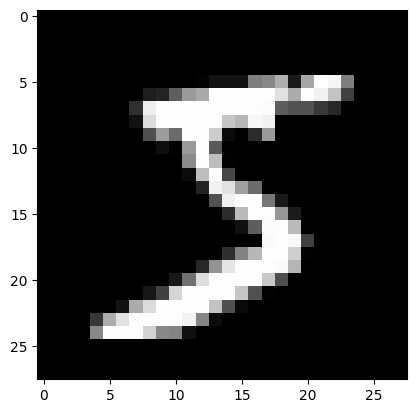

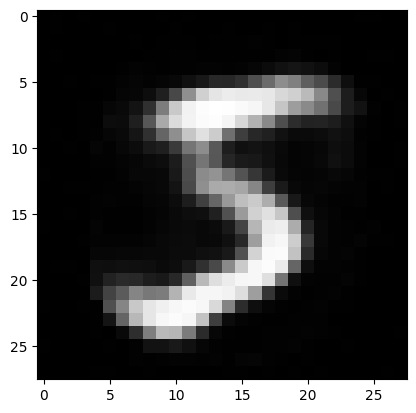

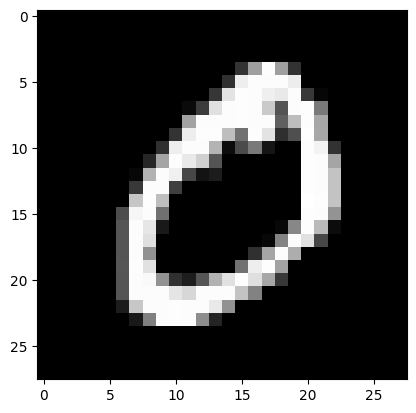

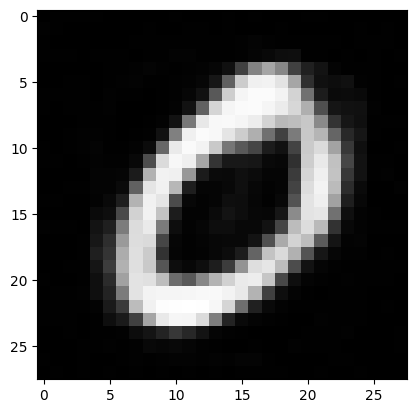

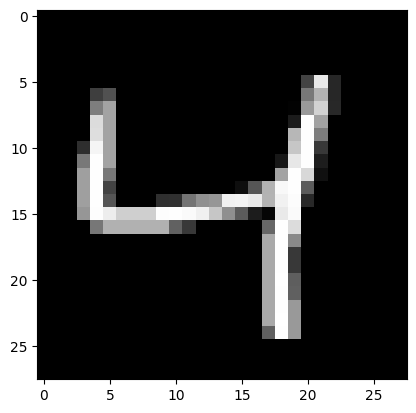

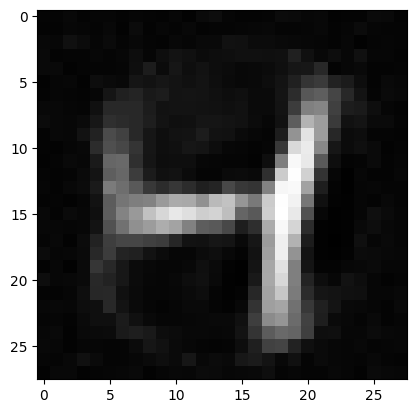

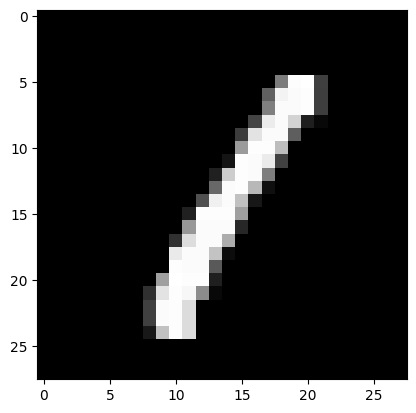

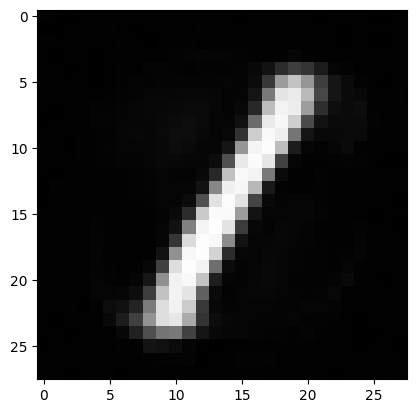

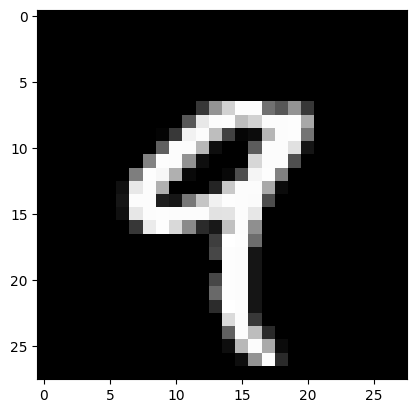

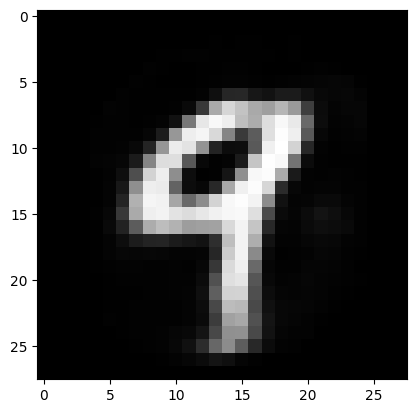

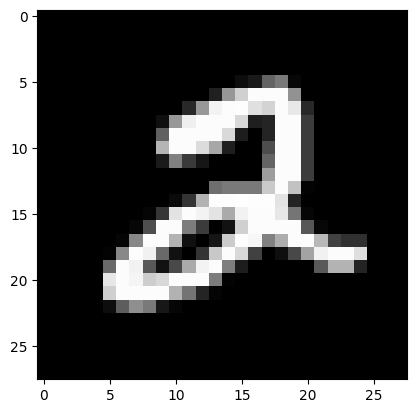

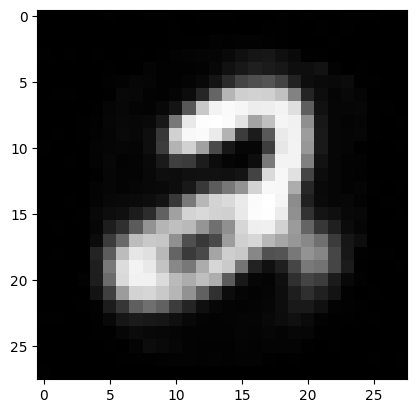

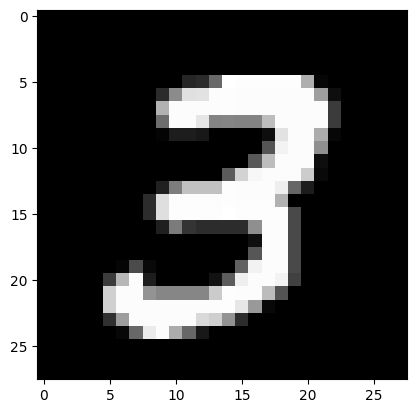

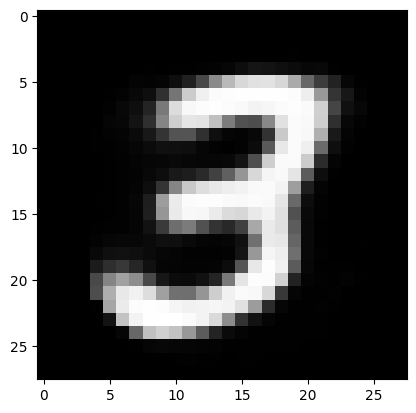

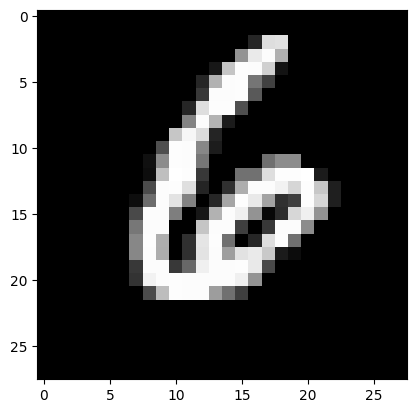

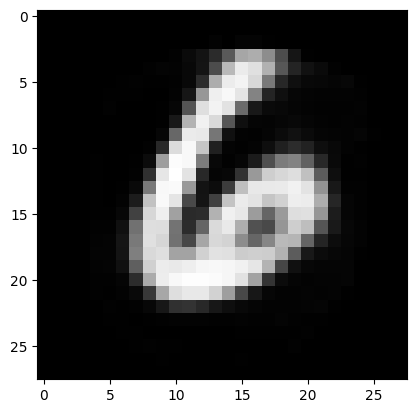

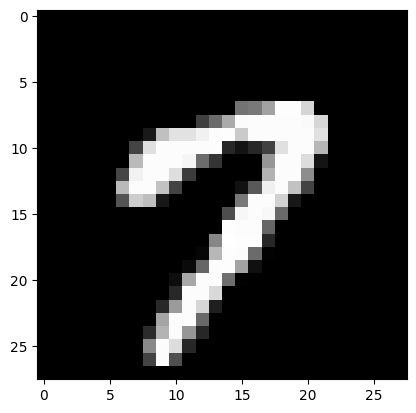

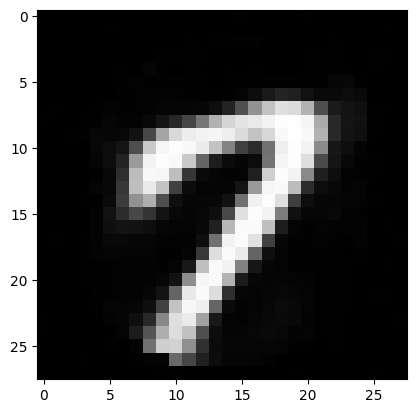

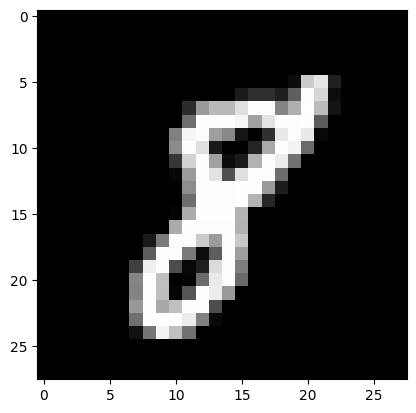

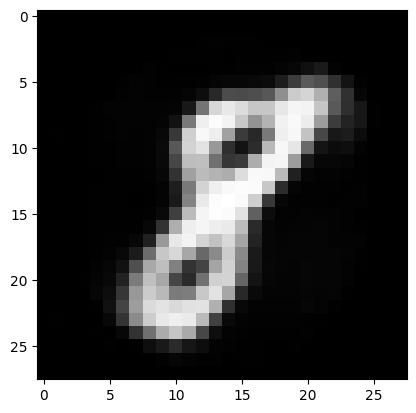

In [11]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre1", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e1_reconstructed = model.decoder_layer_1(e1)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	# To view it:
	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

## Autoencoder Layer 2

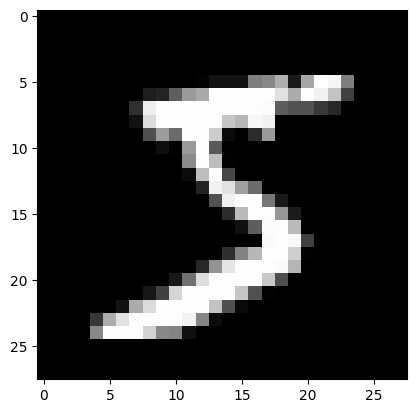

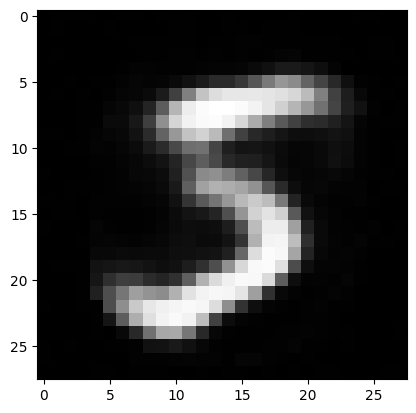

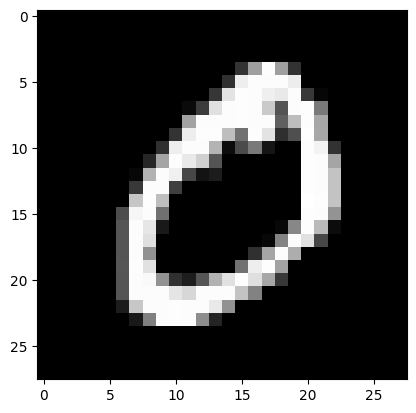

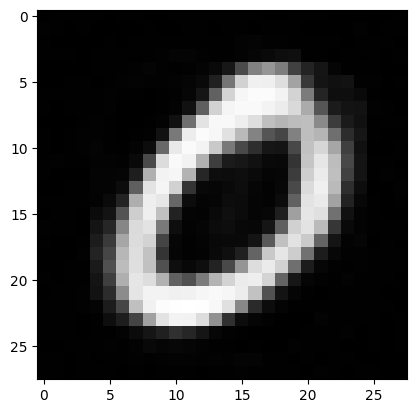

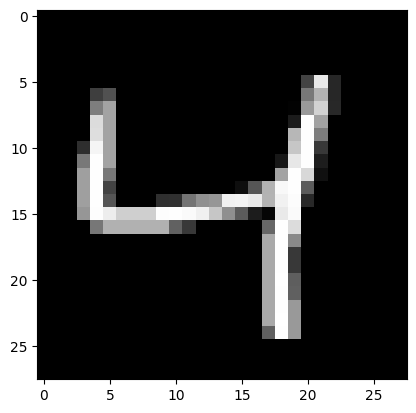

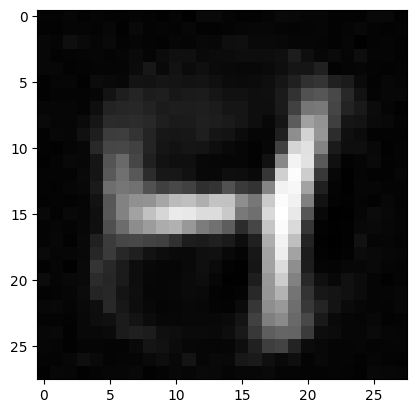

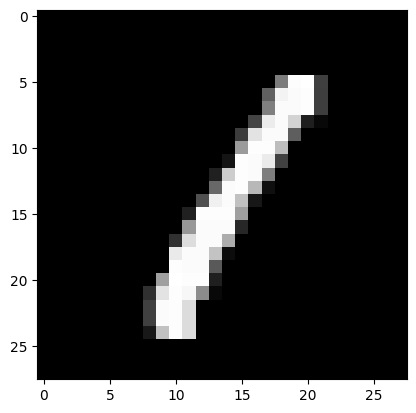

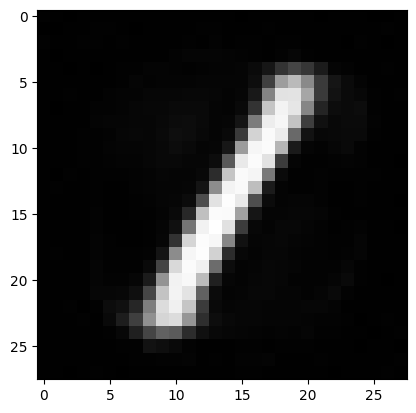

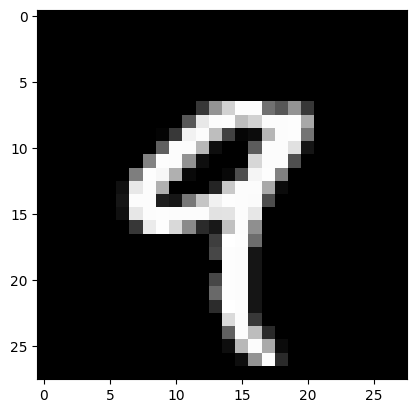

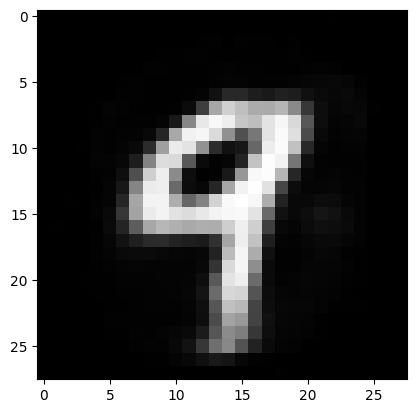

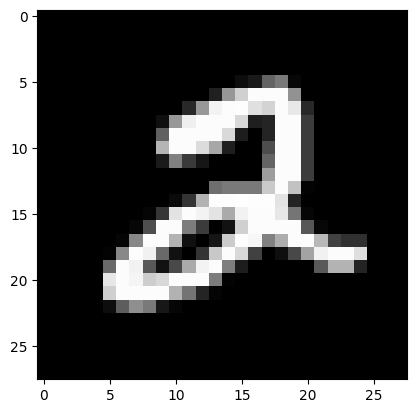

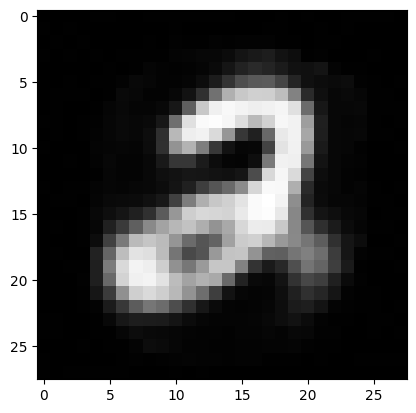

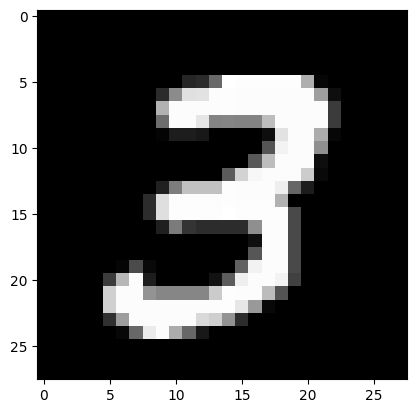

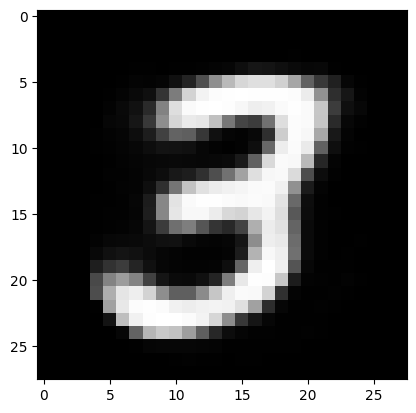

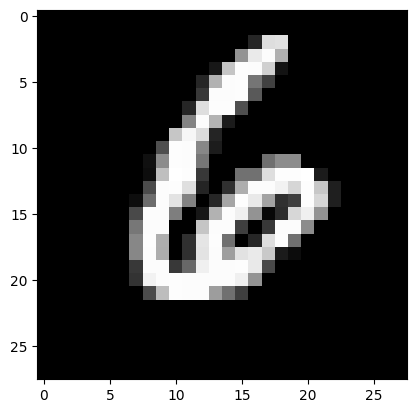

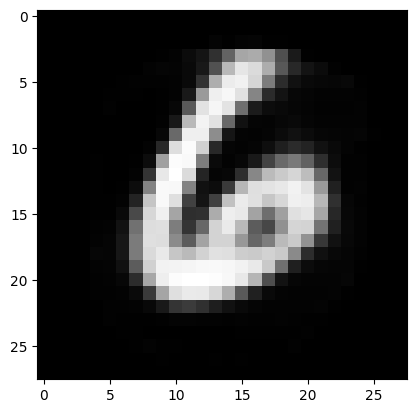

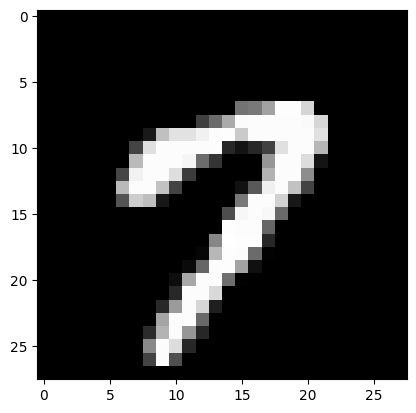

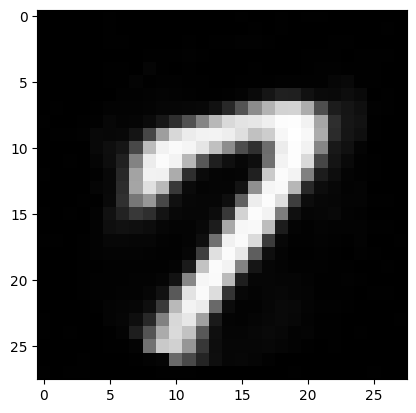

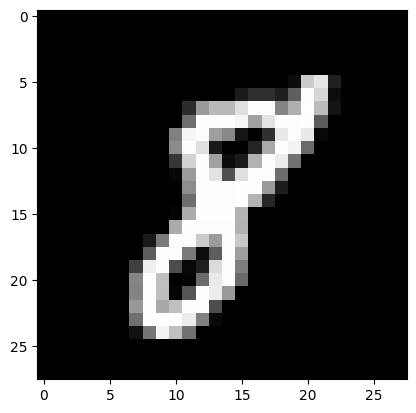

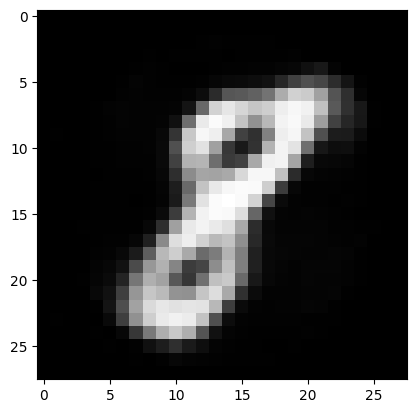

In [12]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre2", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)

		e2_reconstructed = model.decoder_layer_2(e2)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

## Autoencoder Layer 3

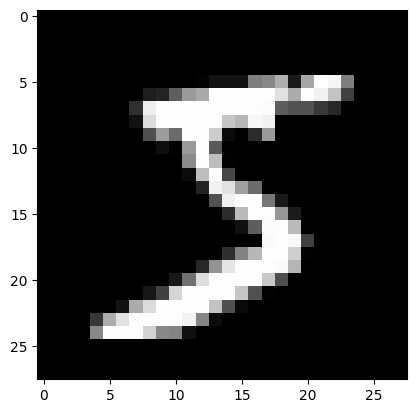

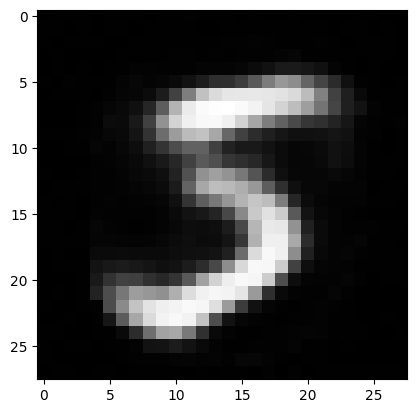

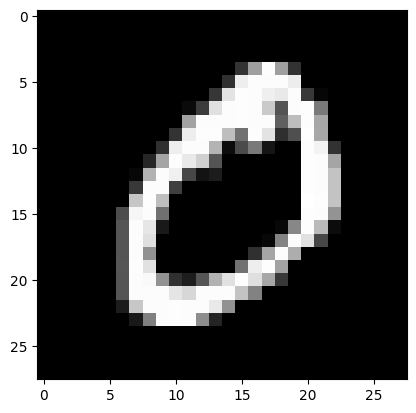

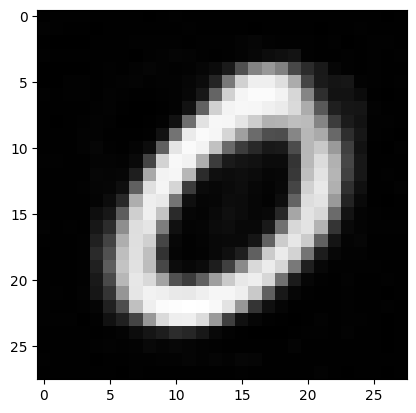

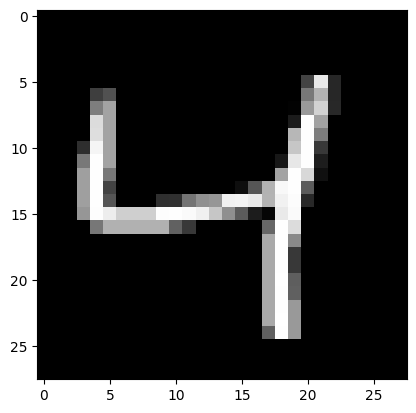

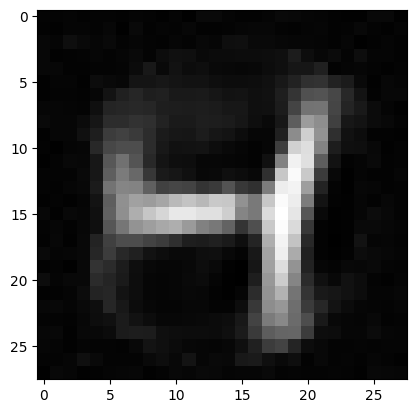

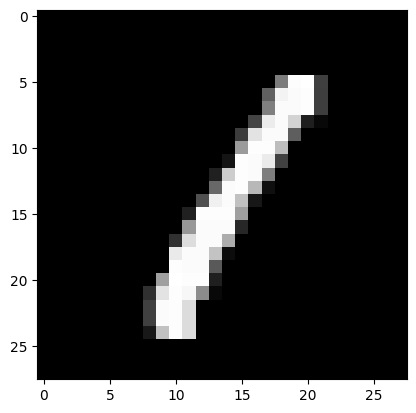

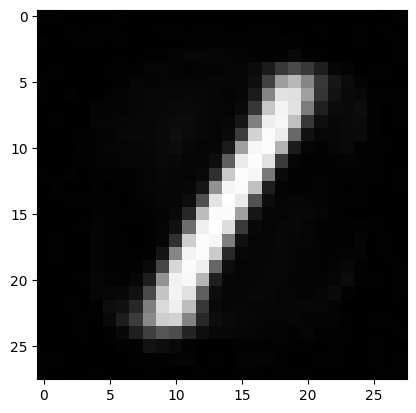

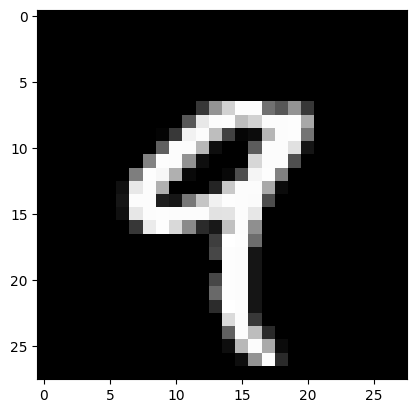

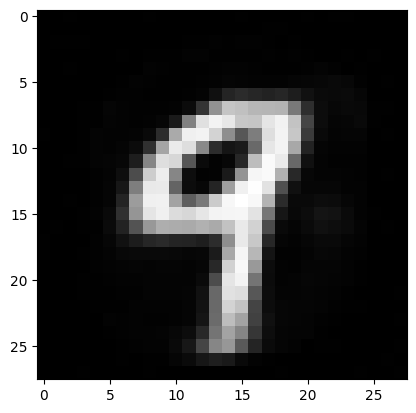

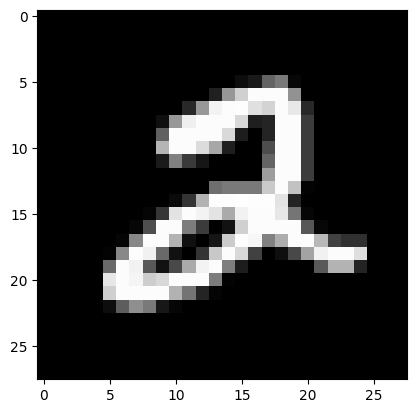

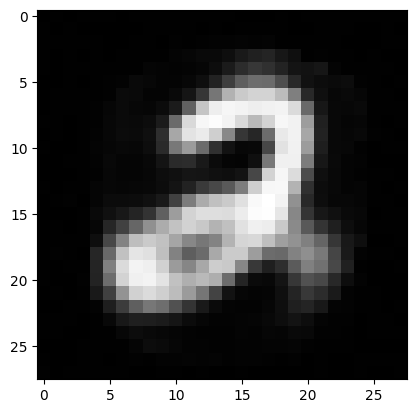

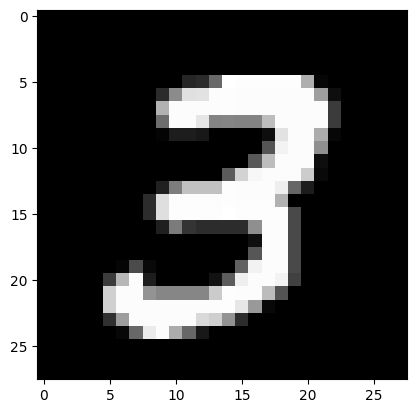

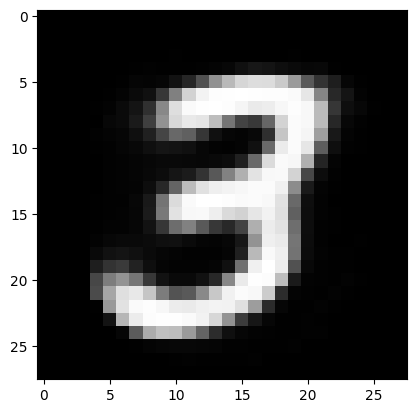

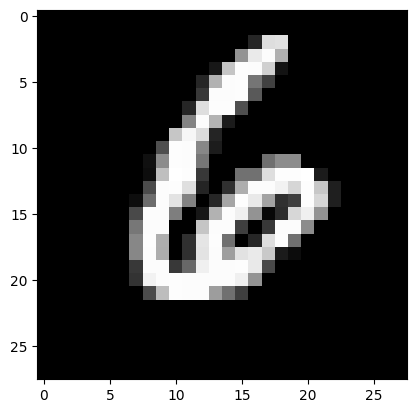

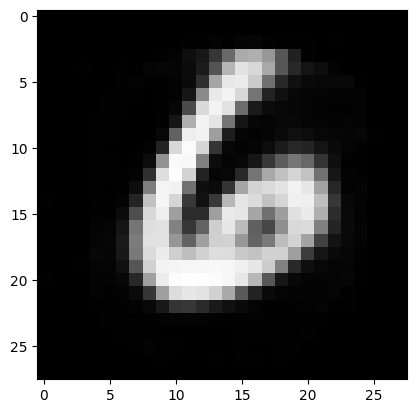

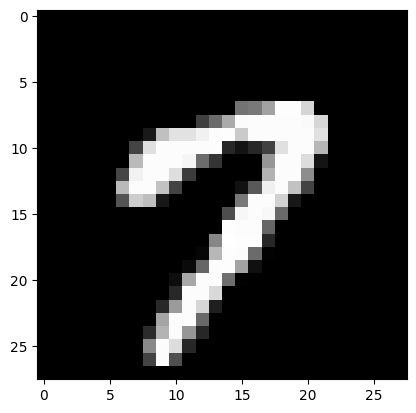

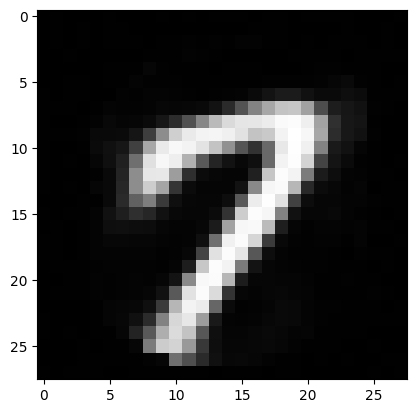

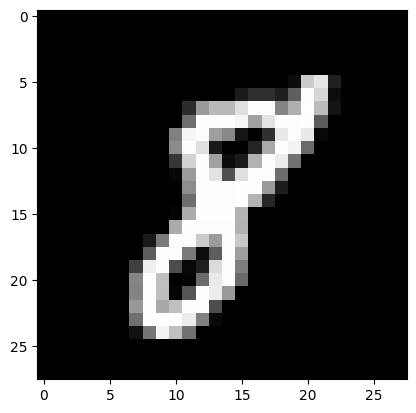

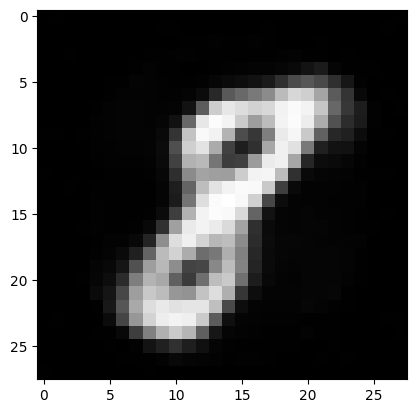

In [13]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre3", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)
		e3 = model.encoder_layer_3(e2)

		e3_reconstructed = model.decoder_layer_3(e3)
		e2_reconstructed = model.decoder_layer_2(e3_reconstructed)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

## Autoencoder Layer 4

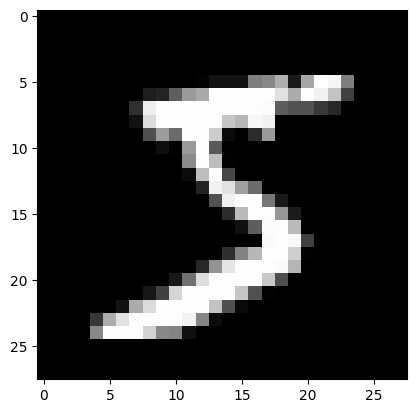

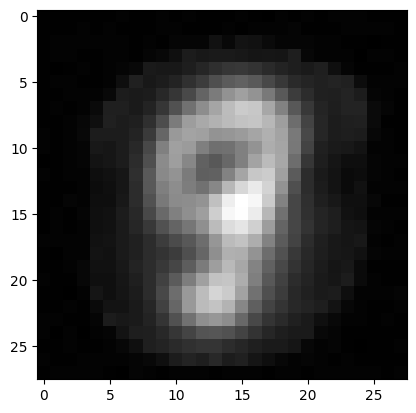

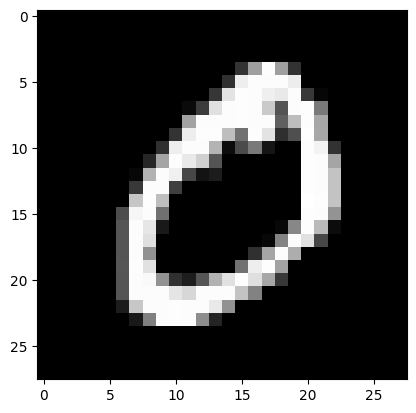

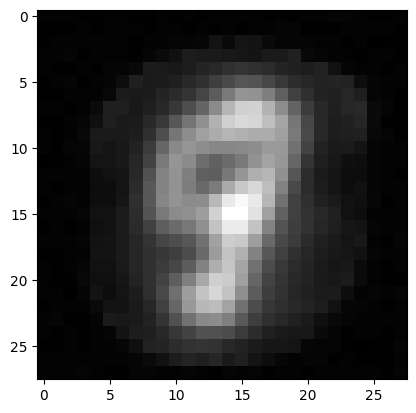

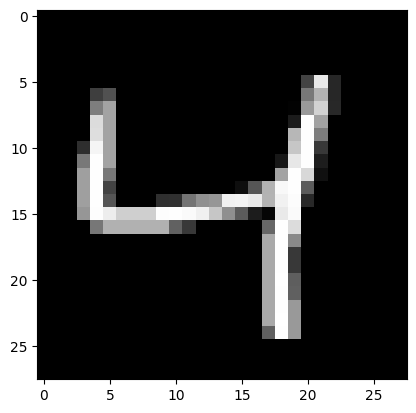

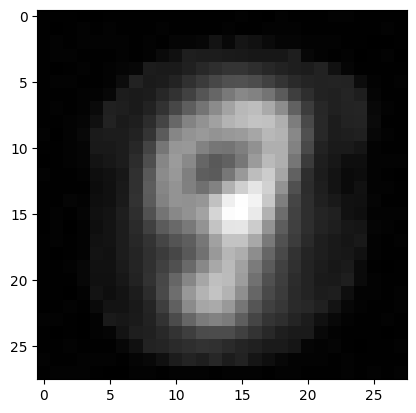

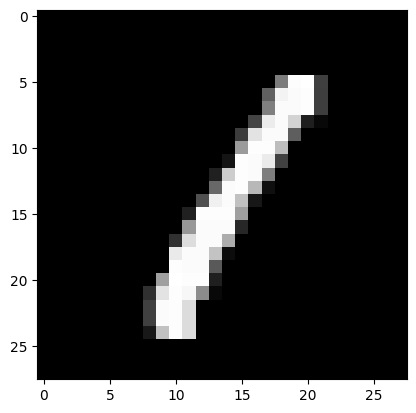

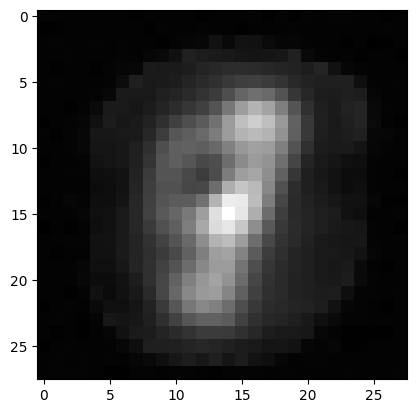

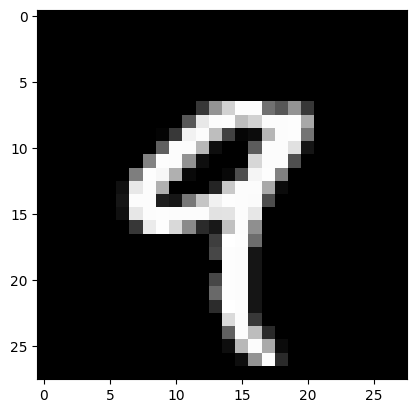

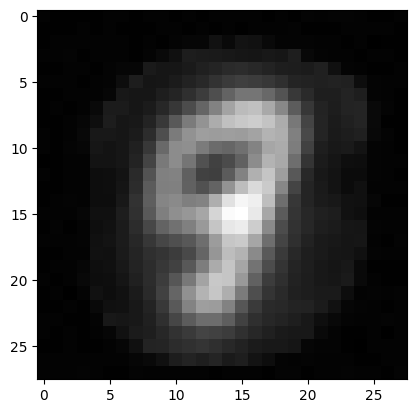

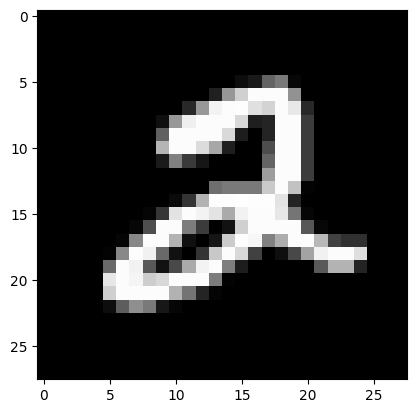

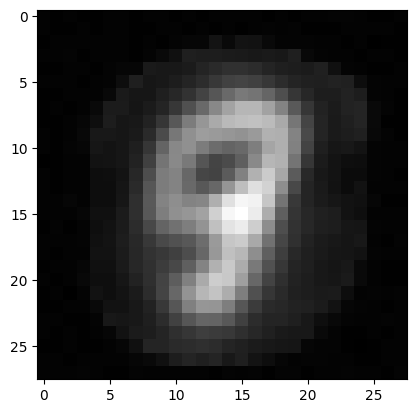

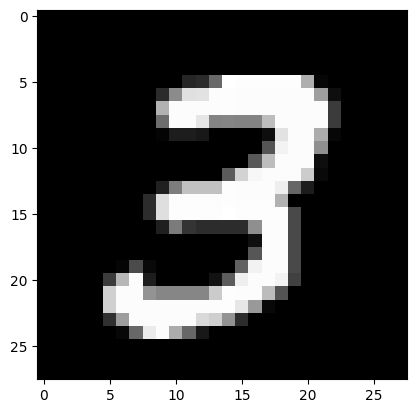

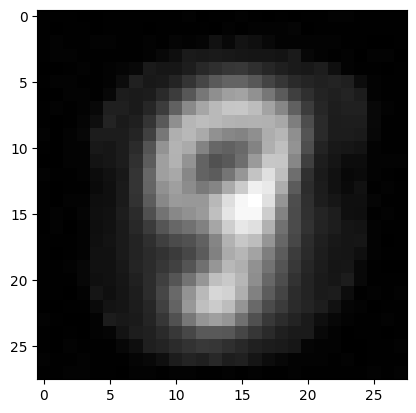

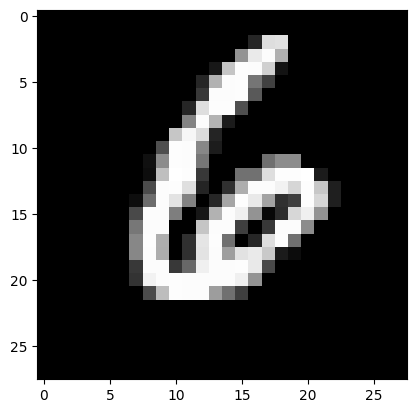

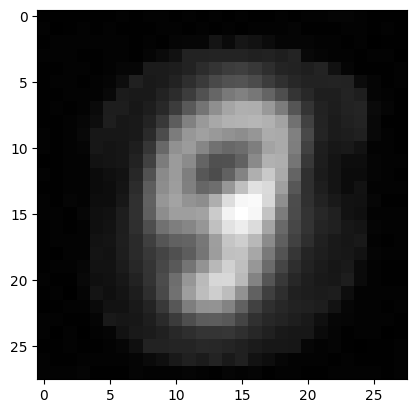

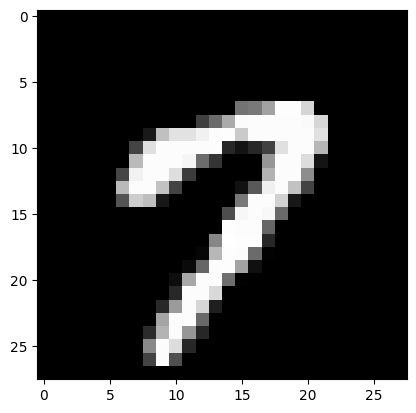

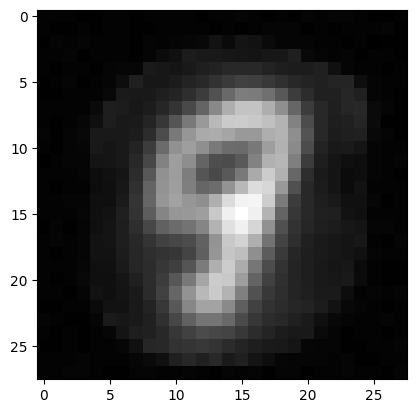

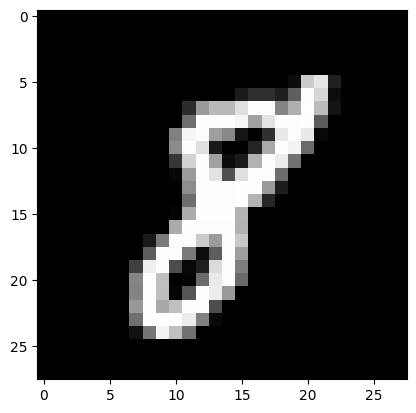

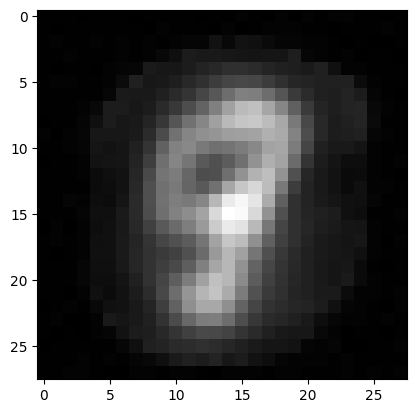

In [14]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre4", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)
		e3 = model.encoder_layer_3(e2)
		e4 = model.encoder_layer_4(e3)

		e4_reconstructed = model.decoder_layer_4(e4)
		e3_reconstructed = model.decoder_layer_3(e4_reconstructed)
		e2_reconstructed = model.decoder_layer_2(e3_reconstructed)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

## Finetuned

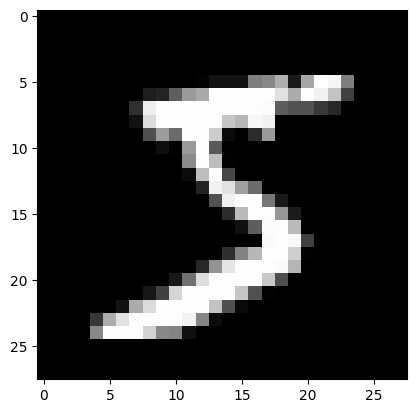

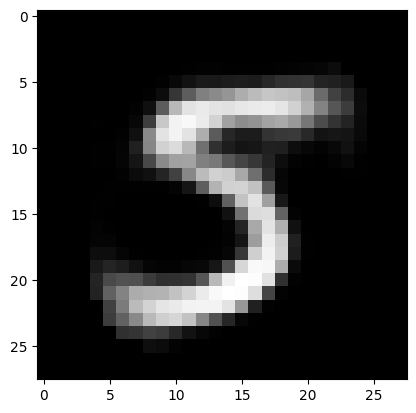

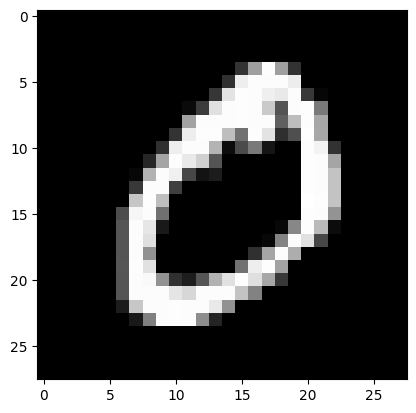

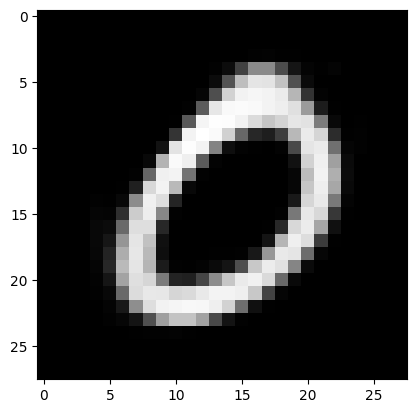

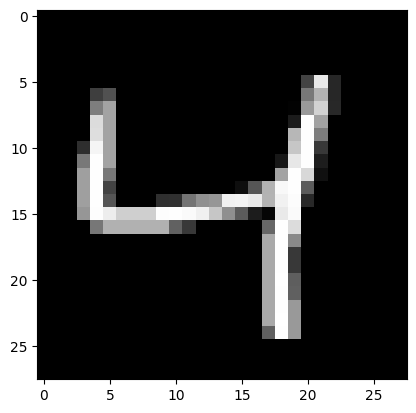

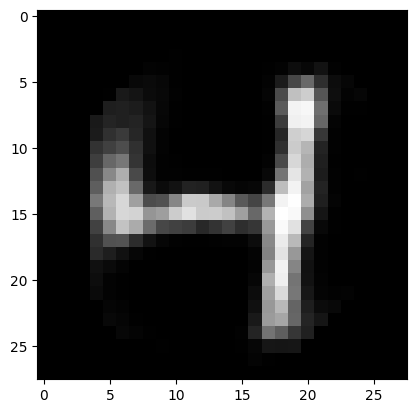

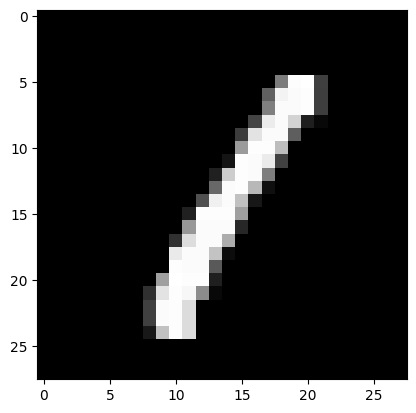

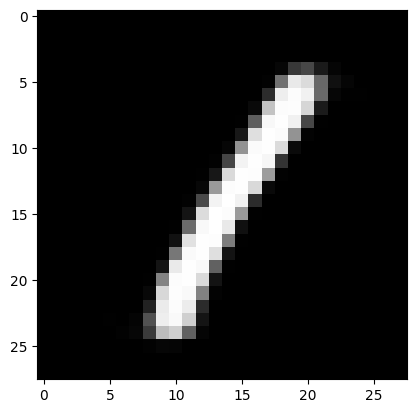

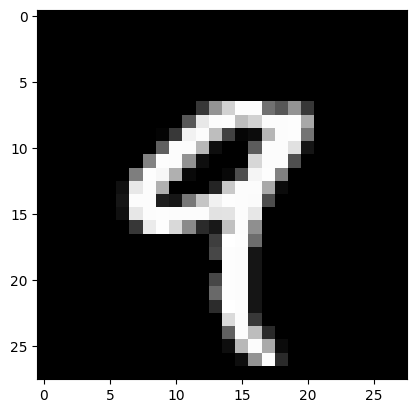

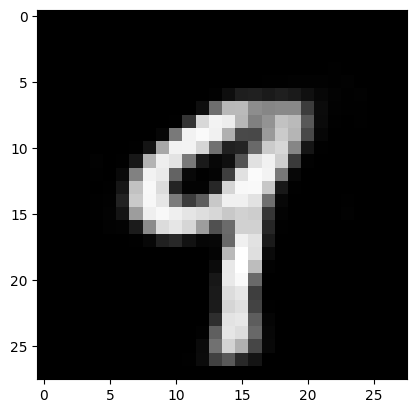

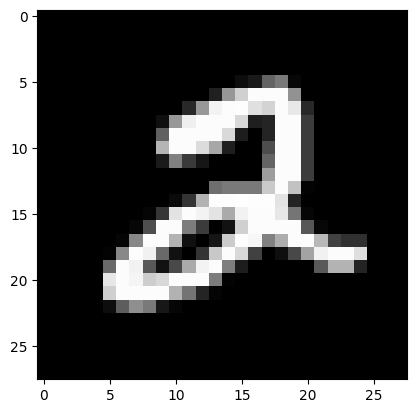

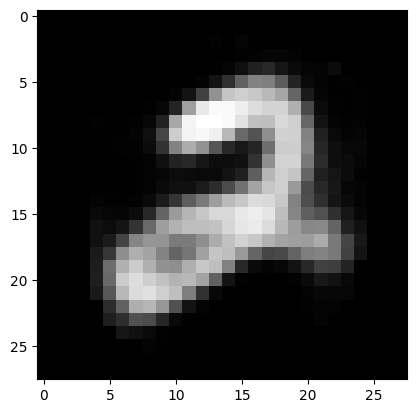

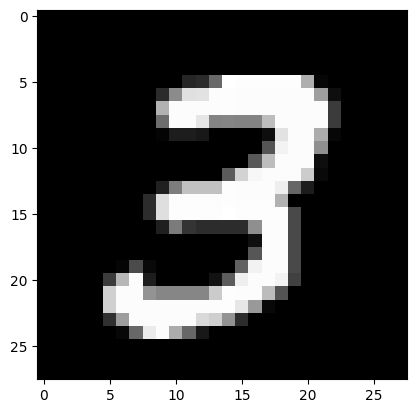

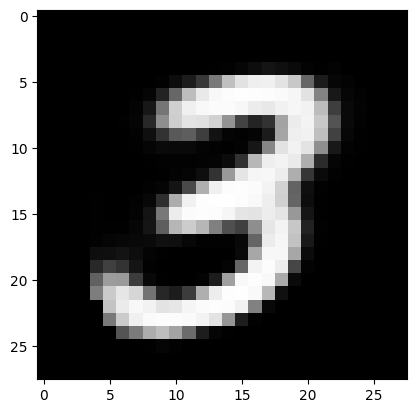

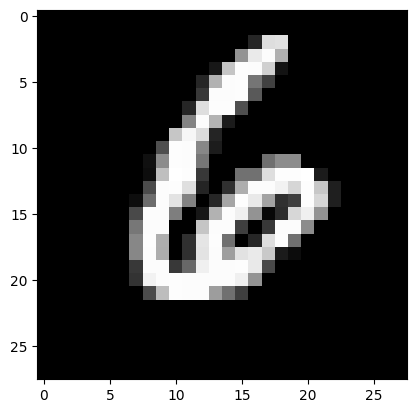

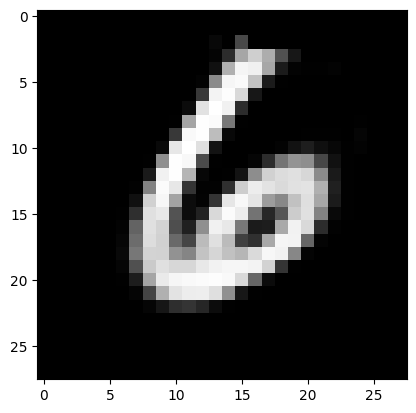

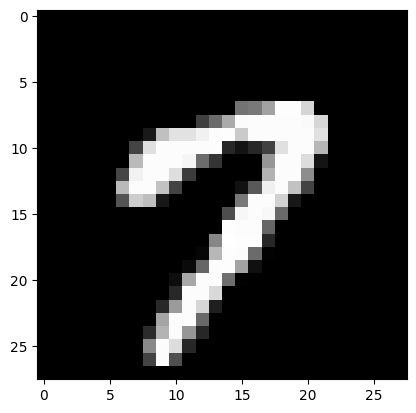

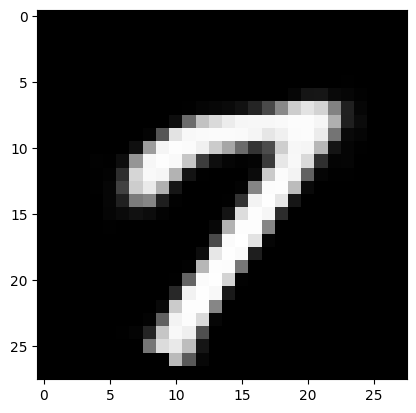

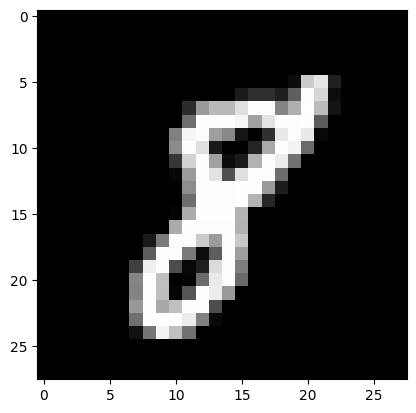

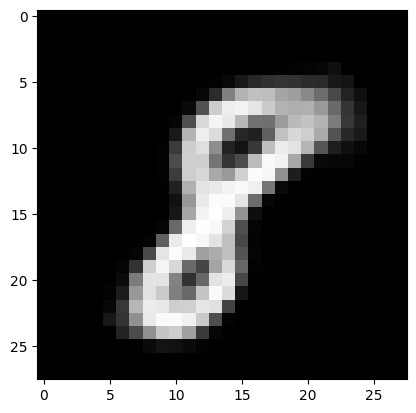

In [15]:
model.load_state_dict(torch.load("./models/" + activation_func + "/finetuned", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)
		reconstructed = model(image_tensor)

	reconstructed = torch.unflatten(reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

# Clustering

## KMeans

In [16]:
model = SAE()
model.to(device)

model.load_state_dict(
    torch.load("./models/" + activation_func + "/finetuned", weights_only = True)
)

model.eval()

all_z = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in dataloader:
        images = torch.flatten(images, start_dim = 1).to(device)

        z = model.encode(images)

        all_z.append(z.cpu().numpy())
        all_labels.append(labels.numpy())

Z = np.concatenate(all_z, axis = 0)
y_true = np.concatenate(all_labels, axis = 0)

print(Z.shape)
print(y_true.shape)

(70000, 10)
(70000,)


In [17]:
from sklearn.cluster import KMeans

n_clusters = 10

kmeans = KMeans(
    n_clusters = n_clusters,
    n_init = 20,
    random_state = 42
)

cluster_labels = kmeans.fit_predict(Z)

centroids = kmeans.cluster_centers_

print(cluster_labels.shape)
print(centroids.shape)

(70000,)
(10, 10)


In [18]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)

print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")

ARI: 0.6010
NMI: 0.6687


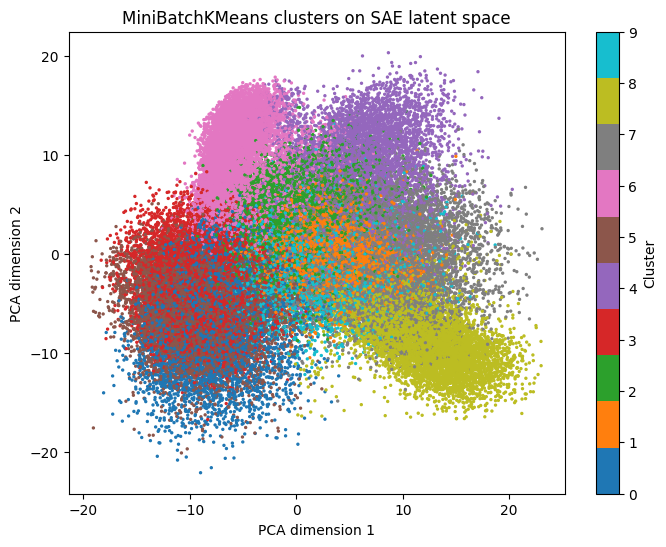

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components = 2, random_state = 42)
Z_2d = pca.fit_transform(Z)

plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("MiniBatchKMeans clusters on SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

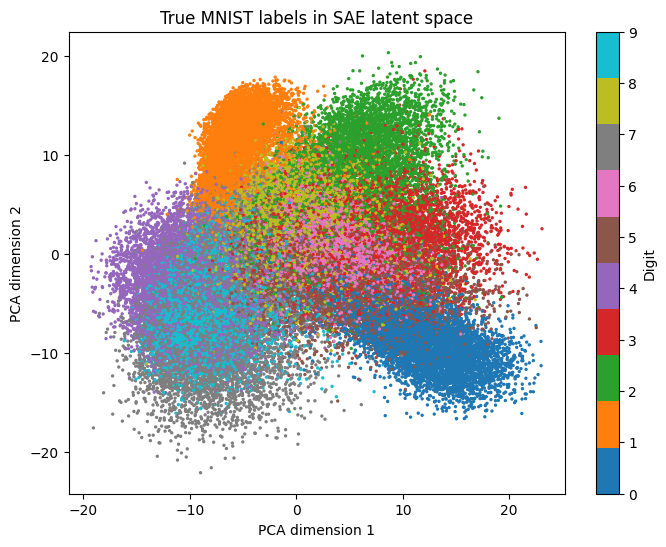

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("True MNIST labels in SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Digit")
plt.show()

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

tsne = TSNE(
    n_components = 2,
    perplexity = 30,
    learning_rate = "auto",
    init = "pca",
    random_state = 42
)

Z_tsne = tsne.fit_transform(Z)

print(Z_tsne.shape)

(70000, 2)


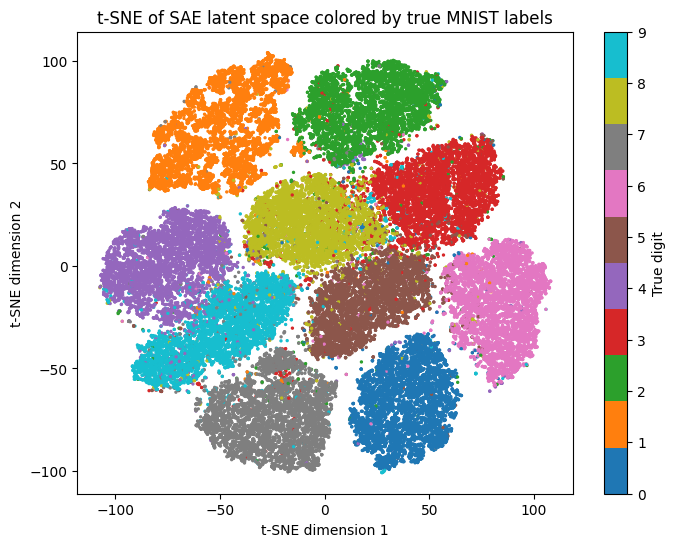

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by true MNIST labels")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "True digit")
plt.show()

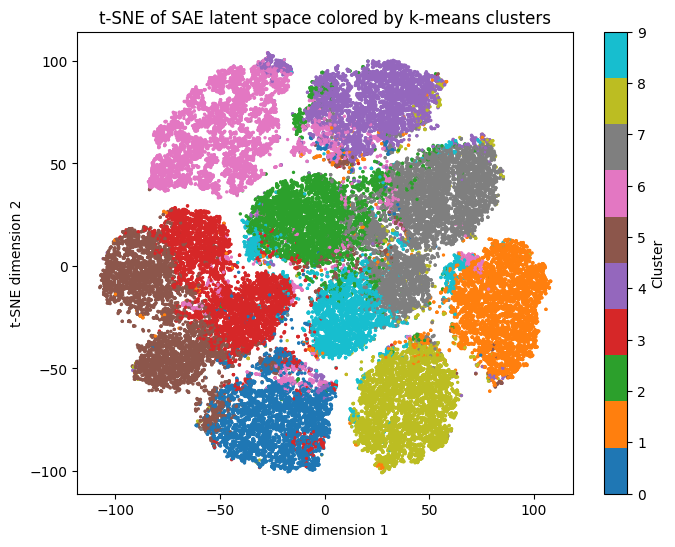

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by k-means clusters")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

In [24]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix
import numpy as np

def clustering_accuracy(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-cm)
    return cm[row_ind, col_ind].sum() / y_true.size

acc = clustering_accuracy(y_true, cluster_labels)

print(f"Clustering Accuracy: {acc:.4f}")

Clustering Accuracy: 0.7544


In [ ]:
import pandas as pd

cluster_digit_counts = pd.crosstab(
    pd.Series(cluster_labels, name = "Cluster"),
    pd.Series(y_true, name = "True digit")
)

cluster_digit_counts

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,2,1,102,50,2,5,1,5660,15,177
1,211,15,118,25,94,139,6247,2,38,13
2,43,11,317,484,1,283,23,17,5166,59
3,7,13,9,19,2917,56,1,420,174,3489
4,16,319,5474,167,19,8,34,124,54,18
5,5,6,107,88,3672,120,28,673,113,2911
6,8,7489,625,223,104,34,162,342,179,82
7,75,12,90,5851,0,2219,13,8,665,123
8,6392,0,131,51,4,83,63,23,15,41


In [ ]:
cluster_digit_percentages = cluster_digit_counts.div(
    cluster_digit_counts.sum(axis = 1),
    axis = 0
)

cluster_digit_percentages.round(2)

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.00,0.00,0.02,0.01,0.00,0.00,0.00,0.94,0.00,0.03
1,0.03,0.00,0.02,0.00,0.01,0.02,0.91,0.00,0.01,0.00
2,0.01,0.00,0.05,0.08,0.00,0.04,0.00,0.00,0.81,0.01
3,0.00,0.00,0.00,0.00,0.41,0.01,0.00,0.06,0.02,0.49
4,0.00,0.05,0.88,0.03,0.00,0.00,0.01,0.02,0.01,0.00
5,0.00,0.00,0.01,0.01,0.48,0.02,0.00,0.09,0.01,0.38
6,0.00,0.81,0.07,0.02,0.01,0.00,0.02,0.04,0.02,0.01
7,0.01,0.00,0.01,0.65,0.00,0.25,0.00,0.00,0.07,0.01
8,0.94,0.00,0.02,0.01,0.00,0.01,0.01,0.00,0.00,0.01
